# 11 — exp1 heading scan: the learned boundary

The server campaign (250 samples, 10^5 encounters each, no early stopping). The surrogate model is refitted from the run's samples (`results/exp1_heading/campaign/store.jsonl`) with the run's own settings. P(LoS) is shown as probabilities.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mvlse import fit_surrogate

sys.path.insert(0, str(Path.cwd().parent))
import config

RUN_DIR = Path.cwd().parent / "results" / "exp1_heading" / "campaign"   # copied from the server
RUN, STORE = RUN_DIR / "run.json", RUN_DIR / "store.jsonl"
assert STORE.exists(), f"copy results/exp1_heading/campaign/ from the server to {RUN_DIR}"

run = json.loads(RUN.read_text())
records = [json.loads(line) for line in STORE.read_text().splitlines() if line.strip()]
P = config.EXPERIMENTS["exp1_heading"]
space = config.space_of(P["space"])
TAU = config.TAU
w = space.encode([r["point"] for r in records])
y = np.array([r["y"] for r in records])
samples = pd.DataFrame([r["point"] for r in records]).assign(y=y, p_los=10.0 ** y)
samples["speed_kt"] = (samples["speed"] / config.KT).round().astype(int)

print(f"{run['experiment']}/{run['tag']}: {run['outcome']['n_evaluations']} samples, stop: {run['outcome']['stop_reason']}, "
      f"final max straddle {run['outcome']['final_max_straddle']:+.2f}, commits {run['code']['mvlse']['commit'][:7]} / "
      f"{run['code']['blueskycdarr']['commit'][:7]}")
print(f"store: {len(records)} samples; {np.sum(y <= TAU)} acceptable (P(LoS) <= 1e-3), {np.sum(y > TAU)} not")
print(space.describe())

exp1_heading/campaign: 250 samples, stop: budget (250 evaluations), final max straddle +1.48, commits 566c532 / 030c0f4
store: 250 samples; 125 acceptable (P(LoS) <= 1e-3), 125 not
DesignSpace: q=3 continuous, r=3 discrete, m=36 categories
  normalize = True  (continuous columns mapped to [0, 1])

  column name             nature     physical                     what the model sees
  ------ ---------------- ---------- ---------------------------- ----------------------------
  0      p_reception      continuous [0.1, 1]                     [0, 1]
  1      max_range_m      continuous [300, 15000]                 [0, 1]
  2      dpsi             continuous [2, 180]                     [0, 1]
  3      pos_ci95         ordinal    3.0, 10.0, 30.0, 92.6        level index 0..3
  4      vel_ci95         ordinal    1.0, 3.0, 10.0               level index 0..2
  5      speed            ordinal    10.28888, 20.57776, 30.8...  level index 0..2


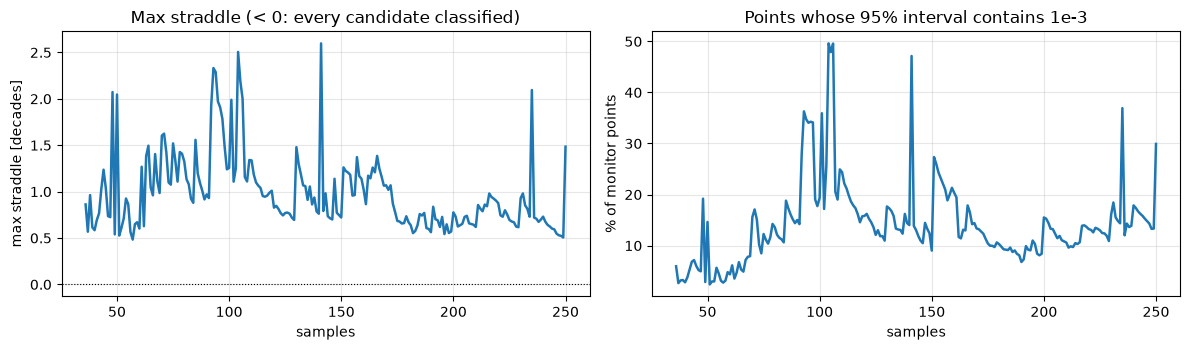

In [2]:
# How far from resolved the boundary was when the 250 samples ran out (run.json rounds).
rounds = pd.DataFrame(run["outcome"]["rounds"])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.6))
a.plot(rounds.n_evaluations, rounds.max_straddle, lw=1.8)
a.axhline(0, color="k", lw=0.8, ls=":")
a.set_xlabel("samples"); a.set_ylabel("max straddle [decades]"); a.set_title("Max straddle (< 0: every candidate classified)")
b.plot(rounds.n_evaluations, 100 * rounds.ambiguous_fraction, lw=1.8)
b.set_xlabel("samples"); b.set_ylabel("% of monitor points"); b.set_title("Points whose 95% interval contains 1e-3")
for ax in (a, b):
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [3]:
# Refit the surrogate model on all 250 samples (the run's own settings), and check it against
# the level correlations the run reported.
model = fit_surrogate(config.LSE["method"], space, w, y, correlation=config.LSE["correlation"],
                      rng=np.random.default_rng(config.SEED), n_starts=12)
mine, theirs = model.level_correlations(), run["outcome"]["level_correlations"]
for name in space.discrete_names:
    levels = [f"{v:g}" for v in space.variable(name).levels]
    print(f"{name}: refit (run.json)")
    print(pd.DataFrame([[f"{a:+.2f} ({b:+.2f})" for a, b in zip(ra, rb)] for ra, rb in zip(mine[name], theirs[name])],
                       index=levels, columns=levels), "\n")

pos_ci95: refit (run.json)
                  3             10             30           92.6
3     +1.00 (+1.00)  +0.99 (+0.99)  +0.97 (+0.97)  +0.93 (+0.93)
10    +0.99 (+0.99)  +1.00 (+1.00)  +0.97 (+0.97)  +0.89 (+0.89)
30    +0.97 (+0.97)  +0.97 (+0.97)  +1.00 (+1.00)  +0.96 (+0.96)
92.6  +0.93 (+0.93)  +0.89 (+0.89)  +0.96 (+0.96)  +1.00 (+1.00) 

vel_ci95: refit (run.json)
                1              3             10
1   +1.00 (+1.00)  +0.66 (+0.66)  -0.27 (-0.27)
3   +0.66 (+0.66)  +1.00 (+1.00)  +0.35 (+0.35)
10  -0.27 (-0.27)  +0.35 (+0.35)  +1.00 (+1.00) 

speed: refit (run.json)
               10.2889        20.5778        30.8666
10.2889  +1.00 (+1.00)  +0.85 (+0.85)  +0.72 (+0.72)
20.5778  +0.85 (+0.85)  +1.00 (+1.00)  +0.97 (+0.97)
30.8666  +0.72 (+0.72)  +0.97 (+0.97)  +1.00 (+1.00) 



In [4]:
# Prediction grid: every category x (p_reception, max_range_m) x dpsi. The requirement is read
# at the worst heading: a CNS combination is acceptable if P(LoS) <= 1e-3 at every heading.
N_P, N_R, N_PSI = 41, 41, 37
p_axis = np.linspace(0, 1, N_P)                     # encoded (unit) coordinates
r_axis = np.linspace(0, 1, N_R)
psi_axis = np.linspace(0, 1, N_PSI)
cont = space.continuous_names                       # (p_reception, max_range_m, dpsi)
disc = space.discrete_names                         # (pos_ci95, vel_ci95, speed)
assert cont == ("p_reception", "max_range_m", "dpsi") and disc == ("pos_ci95", "vel_ci95", "speed")
phys = {n: space.variable(n).from_unit(a) for n, a in zip(cont, (p_axis, r_axis, psi_axis))}

gp, gr, gs = np.meshgrid(p_axis, r_axis, psi_axis, indexing="ij")
base = np.column_stack([gp.ravel(), gr.ravel(), gs.ravel()])
MU, SD = {}, {}
for cat in space.categories:
    wq = np.column_stack([base, np.tile(np.array(cat, float), (len(base), 1))])
    mu, sd = model.predict(wq)
    MU[cat] = mu.reshape(N_P, N_R, N_PSI)
    SD[cat] = sd.reshape(N_P, N_R, N_PSI)
levels = {n: space.variable(n).levels for n in disc}
kt = lambda s: f"{s / config.KT:.0f} kt"
print(f"{len(MU)} categories x {len(base)} points predicted")

36 categories x 62197 points predicted


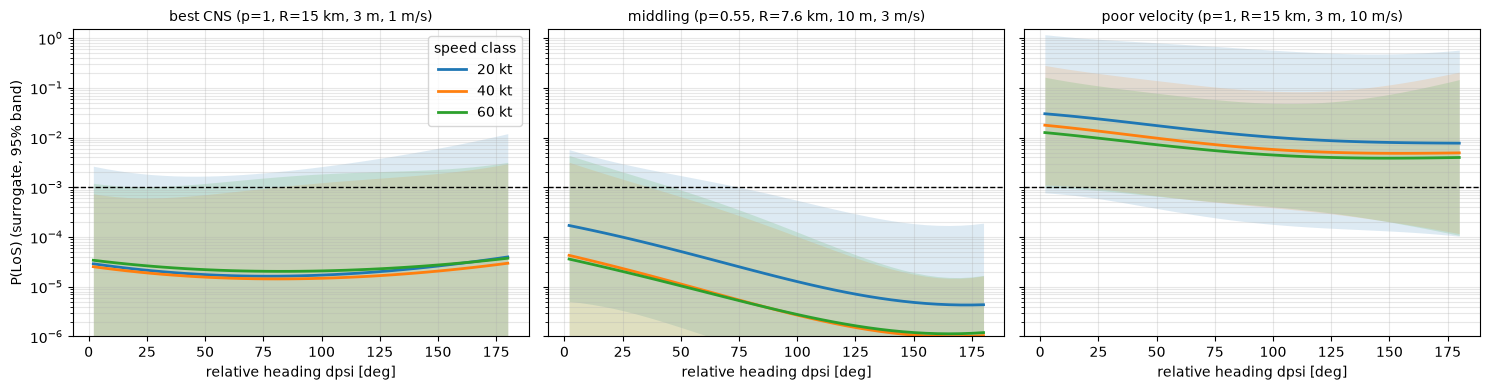

,speed,worst dpsi (median over CNS grid)
0,20 kt,2.000000
1,40 kt,26.722222
2,60 kt,56.388889


In [5]:
# Which heading is worst? P(LoS) against dpsi for each speed class, at three CNS qualities.
cases = {"best CNS (p=1, R=15 km, 3 m, 1 m/s)": (N_P - 1, N_R - 1, 0, 0),
         "middling (p=0.55, R=7.6 km, 10 m, 3 m/s)": (N_P // 2, N_R // 2, 1, 1),
         "poor velocity (p=1, R=15 km, 3 m, 10 m/s)": (N_P - 1, N_R - 1, 0, 2)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (label, (ip, ir, ipos, ivel)) in zip(axes, cases.items()):
    for k, spd in enumerate(levels["speed"]):
        mu, sd = MU[ipos, ivel, k][ip, ir], SD[ipos, ivel, k][ip, ir]
        ax.plot(phys["dpsi"], 10 ** mu, color=f"C{k}", lw=2, label=kt(spd))
        ax.fill_between(phys["dpsi"], 10 ** (mu - 1.96 * sd), 10 ** (mu + 1.96 * sd), color=f"C{k}", alpha=0.15, lw=0)
    s = samples
    ax.axhline(10 ** TAU, color="k", lw=1, ls="--")
    ax.set_yscale("log"); ax.set_ylim(1e-6, 1.5); ax.set_xlabel("relative heading dpsi [deg]"); ax.set_title(label, fontsize=10)
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("P(LoS) (surrogate, 95% band)"); axes[0].legend(title="speed class")
plt.tight_layout(); plt.show()

worst = []
for k, spd in enumerate(levels["speed"]):
    mu = np.stack([MU[i, j, k] for i in range(4) for j in range(3)])     # over pos x vel
    worst.append({"speed": kt(spd), "worst dpsi (median over CNS grid)": float(np.median(phys["dpsi"][mu.argmax(axis=-1)]))})
pd.DataFrame(worst)

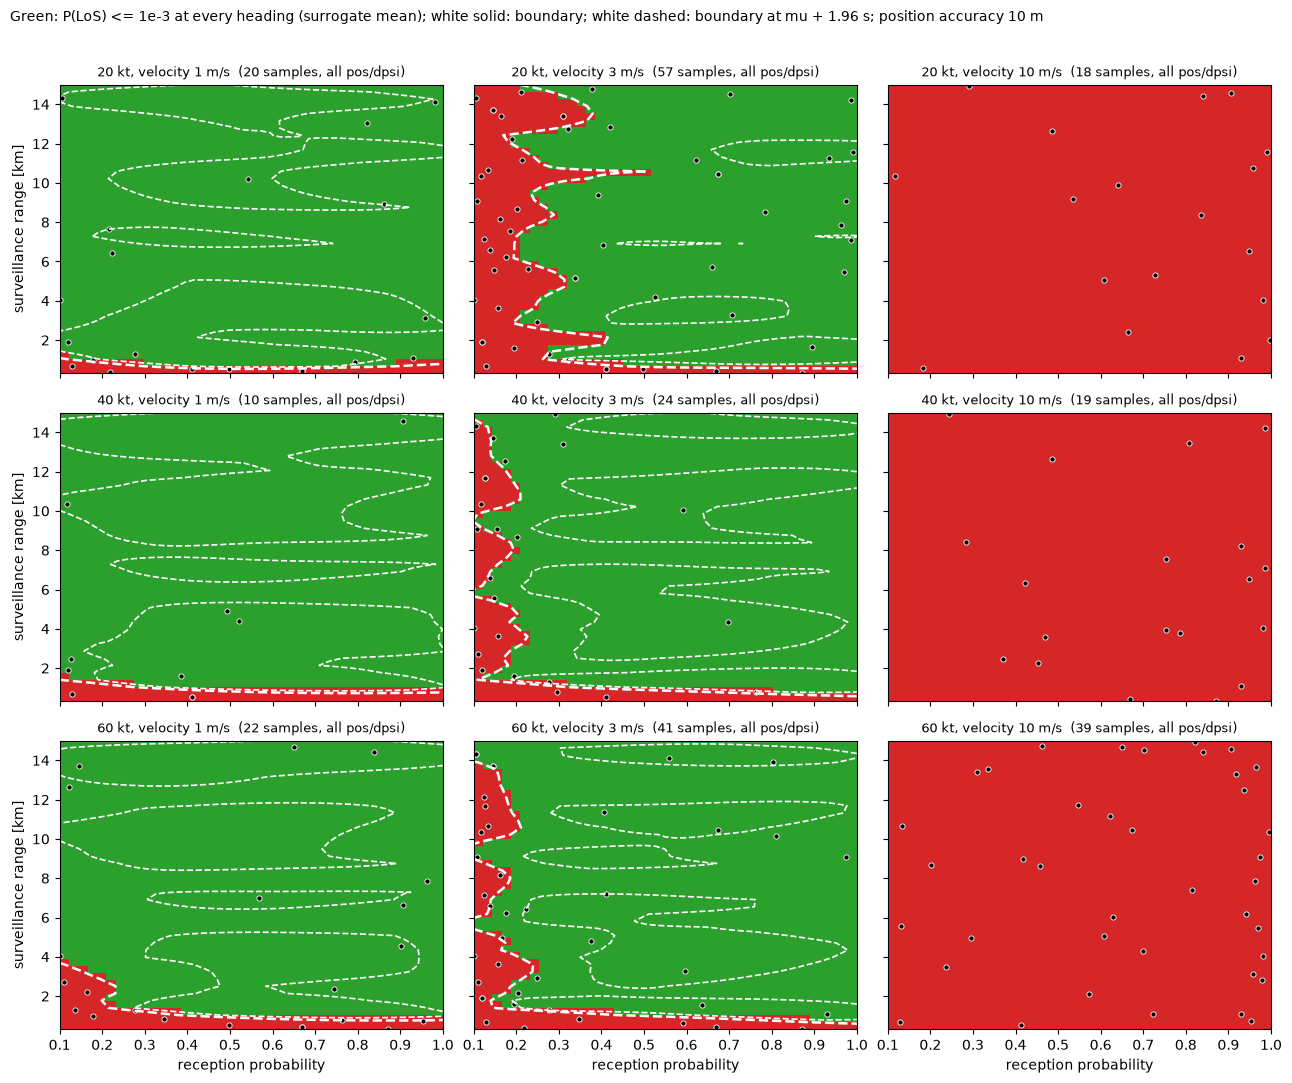

In [6]:
# The requirement: acceptable (green) where P(LoS) <= 1e-3 at EVERY heading (worst case over dpsi),
# in the reception-range plane. Rows: speed class; columns: velocity accuracy; position accuracy
# fixed (see the next cell for why). Dashed white: the same boundary read at mu + 1.96 s (conservative).
TWO = ListedColormap(["tab:red", "tab:green"])
POS = 1                                                              # pos_ci95 = 10 m
fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharex=True, sharey=True)
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        ax = axes[k, j]
        mu_w = MU[POS, j, k].max(axis=-1)                            # worst heading
        up_w = (MU[POS, j, k] + 1.96 * SD[POS, j, k]).max(axis=-1)
        ax.imshow((mu_w <= TAU).T.astype(float), origin="lower", aspect="auto", cmap=TWO, vmin=0, vmax=1,
                  extent=(phys["p_reception"][0], phys["p_reception"][-1], phys["max_range_m"][0] / 1e3, phys["max_range_m"][-1] / 1e3),
                  interpolation="nearest")
        PR, RR = np.meshgrid(phys["p_reception"], phys["max_range_m"] / 1e3, indexing="ij")
        ax.contour(PR, RR, mu_w, levels=[TAU], colors="white", linewidths=1.8)
        ax.contour(PR, RR, up_w, levels=[TAU], colors="white", linewidths=1.2, linestyles="--")
        sel = (samples.speed_kt == round(spd / config.KT)) & (samples.vel_ci95 == vel)
        ax.scatter(samples.p_reception[sel], samples.max_range_m[sel] / 1e3, s=14, c="black", edgecolors="white", linewidths=0.6)
        ax.set_title(f"{kt(spd)}, velocity {vel:g} m/s  ({sel.sum()} samples, all pos/dpsi)", fontsize=9)
        if k == 2: ax.set_xlabel("reception probability")
        if j == 0: ax.set_ylabel("surveillance range [km]")
fig.suptitle("Green: P(LoS) <= 1e-3 at every heading (surrogate mean); white solid: boundary; white dashed: boundary at "
             "mu + 1.96 s; position accuracy 10 m", x=0.01, ha="left", fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

In [7]:
# How much of the reception-range plane is acceptable, per category (worst heading, surrogate mean).
rows = []
for (ipos, ivel, k), mu in MU.items():
    rows.append({"speed": kt(levels["speed"][k]), "vel_ci95": levels["vel_ci95"][ivel], "pos_ci95": levels["pos_ci95"][ipos],
                 "acceptable share": float(np.mean(mu.max(axis=-1) <= TAU)),
                 "acceptable share (mu + 1.96 s)": float(np.mean((mu + 1.96 * SD[ipos, ivel, k]).max(axis=-1) <= TAU))})
share = pd.DataFrame(rows)
share.to_csv("results/exp1_acceptable_share.csv", index=False)
display(share.pivot_table(index=["speed", "vel_ci95"], columns="pos_ci95", values="acceptable share").round(2))
display(share.pivot_table(index=["speed", "vel_ci95"], columns="pos_ci95", values="acceptable share (mu + 1.96 s)").round(2))

pos_ci95        3.0   10.0  30.0  92.6
speed vel_ci95                        
20 kt 1.0       0.97  0.97  0.97  0.97
      3.0       0.76  0.77  0.81  0.78
      10.0      0.00  0.00  0.00  0.00
40 kt 1.0       0.94  0.95  0.95  0.95
      3.0       0.86  0.88  0.91  0.88
      10.0      0.00  0.00  0.00  0.00
60 kt 1.0       0.93  0.92  0.94  0.94
      3.0       0.87  0.88  0.91  0.90
      10.0      0.00  0.00  0.00  0.00

pos_ci95        3.0   10.0  30.0  92.6
speed vel_ci95                        
20 kt 1.0       0.37  0.40  0.43  0.22
      3.0       0.11  0.11  0.13  0.05
      10.0      0.00  0.00  0.00  0.00
40 kt 1.0       0.55  0.58  0.61  0.42
      3.0       0.35  0.39  0.47  0.30
      10.0      0.00  0.00  0.00  0.00
60 kt 1.0       0.43  0.46  0.48  0.34
      3.0       0.30  0.33  0.42  0.26
      10.0      0.00  0.00  0.00  0.00

## How the requirement is defined over the heading

Three ways to turn P(LoS)(c, ψ) into one number per CNS combination c, all read from the same
surrogate:

* **worst case**: $\max_\psi P(c,\psi)$, safe at every heading in 2–180°;
* **uniform average**: $\int P(c,\psi)\,d\psi / 178°$, every heading equally likely;
* **closing-speed weighted**: $\int P(c,\psi)\,w(\psi)\,d\psi$ with $w \propto v_\mathrm{rel} \propto \sin(\psi/2)$:
  in a random-traffic (gas) model conflicts occur at a rate proportional to the closing speed,
  so slow, near-parallel conflicts are rarer.

Averages are taken over probabilities, not log10 values. The conservative variant uses
$10^{\mu+1.96s}$ at every heading before aggregating.

In [8]:
psi = phys["dpsi"]
W = {"uniform average": np.ones_like(psi) / len(psi),
     "closing-speed weighted": np.sin(np.radians(psi) / 2) / np.sin(np.radians(psi) / 2).sum()}
print("weight of headings below 20 deg:", {k: f"{w[psi < 20].sum():.1%}" for k, w in W.items()})

def aggregate(cat, how, conservative=False):
    """log10 of the heading-aggregated P(LoS) on the reception x range grid."""
    log_p = MU[cat] + (1.96 * SD[cat] if conservative else 0.0)
    if how == "worst case":
        return log_p.max(axis=-1)
    return np.log10((10.0 ** log_p) @ W[how])

HOWS = ["worst case", "uniform average", "closing-speed weighted"]
rows = []
for cat in MU:
    ipos, ivel, k = cat
    for how in HOWS:
        rows.append({"definition": how, "speed": kt(levels["speed"][k]), "vel_ci95": levels["vel_ci95"][ivel],
                     "pos_ci95": levels["pos_ci95"][ipos],
                     "share (mean)": float(np.mean(aggregate(cat, how) <= TAU)),
                     "share (mu + 1.96 s)": float(np.mean(aggregate(cat, how, True) <= TAU))})
defs = pd.DataFrame(rows)
defs.to_csv("results/exp1_requirement_definitions.csv", index=False)
# Position accuracy barely matters (above), so average the share over the four position classes.
display(defs.pivot_table(index=["speed", "vel_ci95"], columns="definition", values="share (mean)").round(2)[HOWS])
display(defs.pivot_table(index=["speed", "vel_ci95"], columns="definition", values="share (mu + 1.96 s)").round(2)[HOWS])

weight of headings below 20 deg: {'uniform average': '10.8%', 'closing-speed weighted': '1.4%'}


definition      worst case  uniform average  closing-speed weighted
speed vel_ci95                                                     
20 kt 1.0             0.97             0.97                    0.97
      3.0             0.78             0.87                    0.89
      10.0            0.00             0.00                    0.00
40 kt 1.0             0.95             0.96                    0.96
      3.0             0.88             0.93                    0.93
      10.0            0.00             0.00                    0.00
60 kt 1.0             0.93             0.95                    0.95
      3.0             0.89             0.93                    0.92
      10.0            0.00             0.00                    0.00

definition      worst case  uniform average  closing-speed weighted
speed vel_ci95                                                     
20 kt 1.0             0.36             0.75                    0.77
      3.0             0.10             0.42                    0.46
      10.0            0.00             0.00                    0.00
40 kt 1.0             0.54             0.82                    0.82
      3.0             0.38             0.71                    0.73
      10.0            0.00             0.00                    0.00
60 kt 1.0             0.43             0.71                    0.72
      3.0             0.33             0.64                    0.66
      10.0            0.00             0.00                    0.00

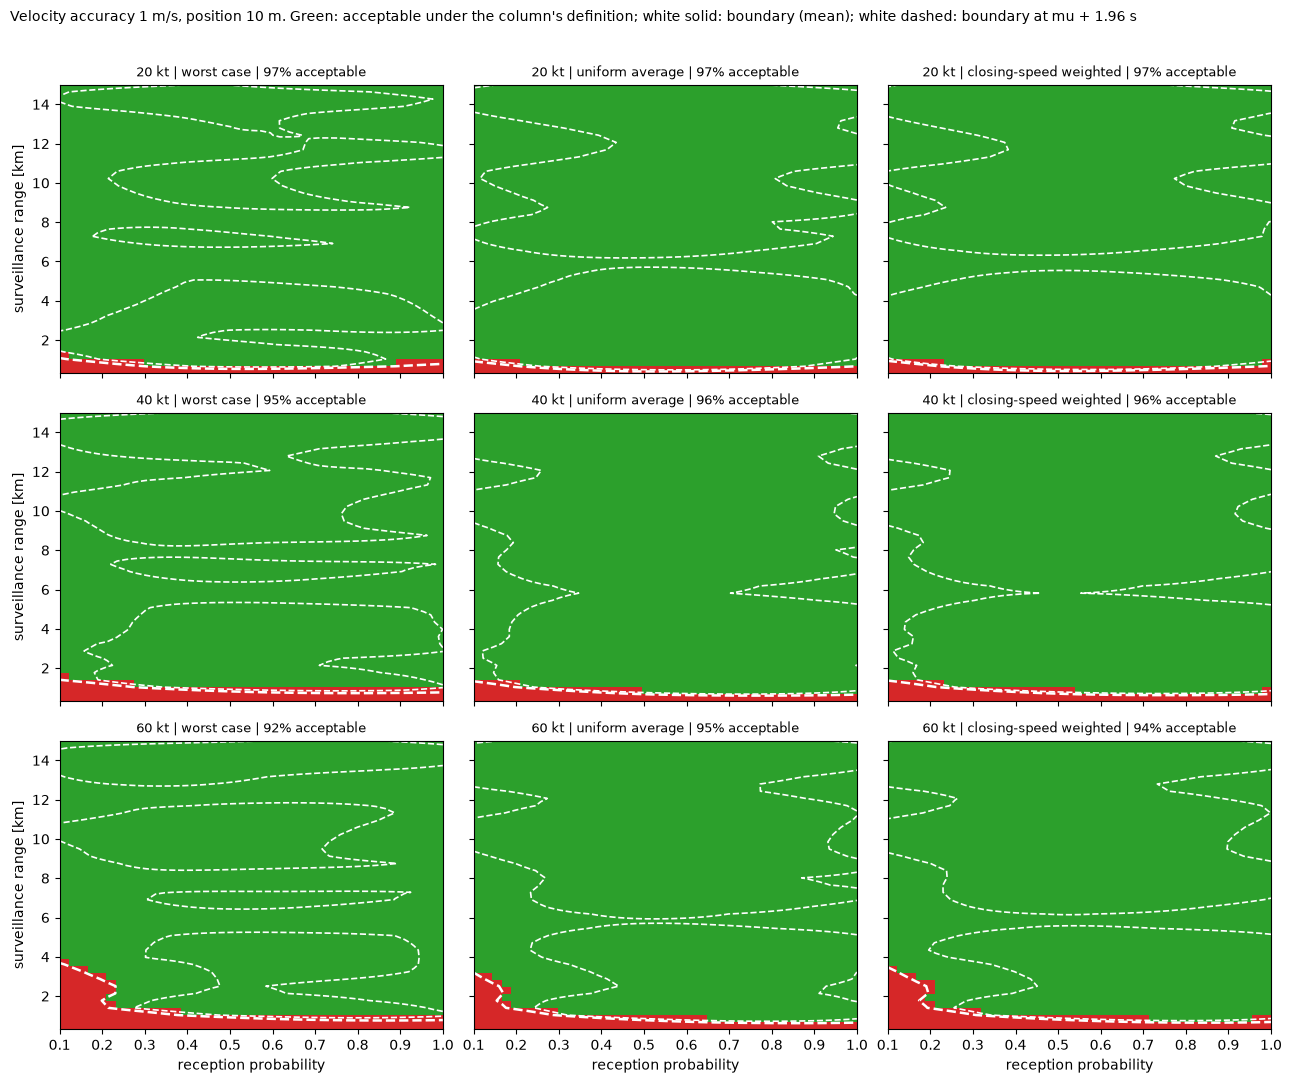

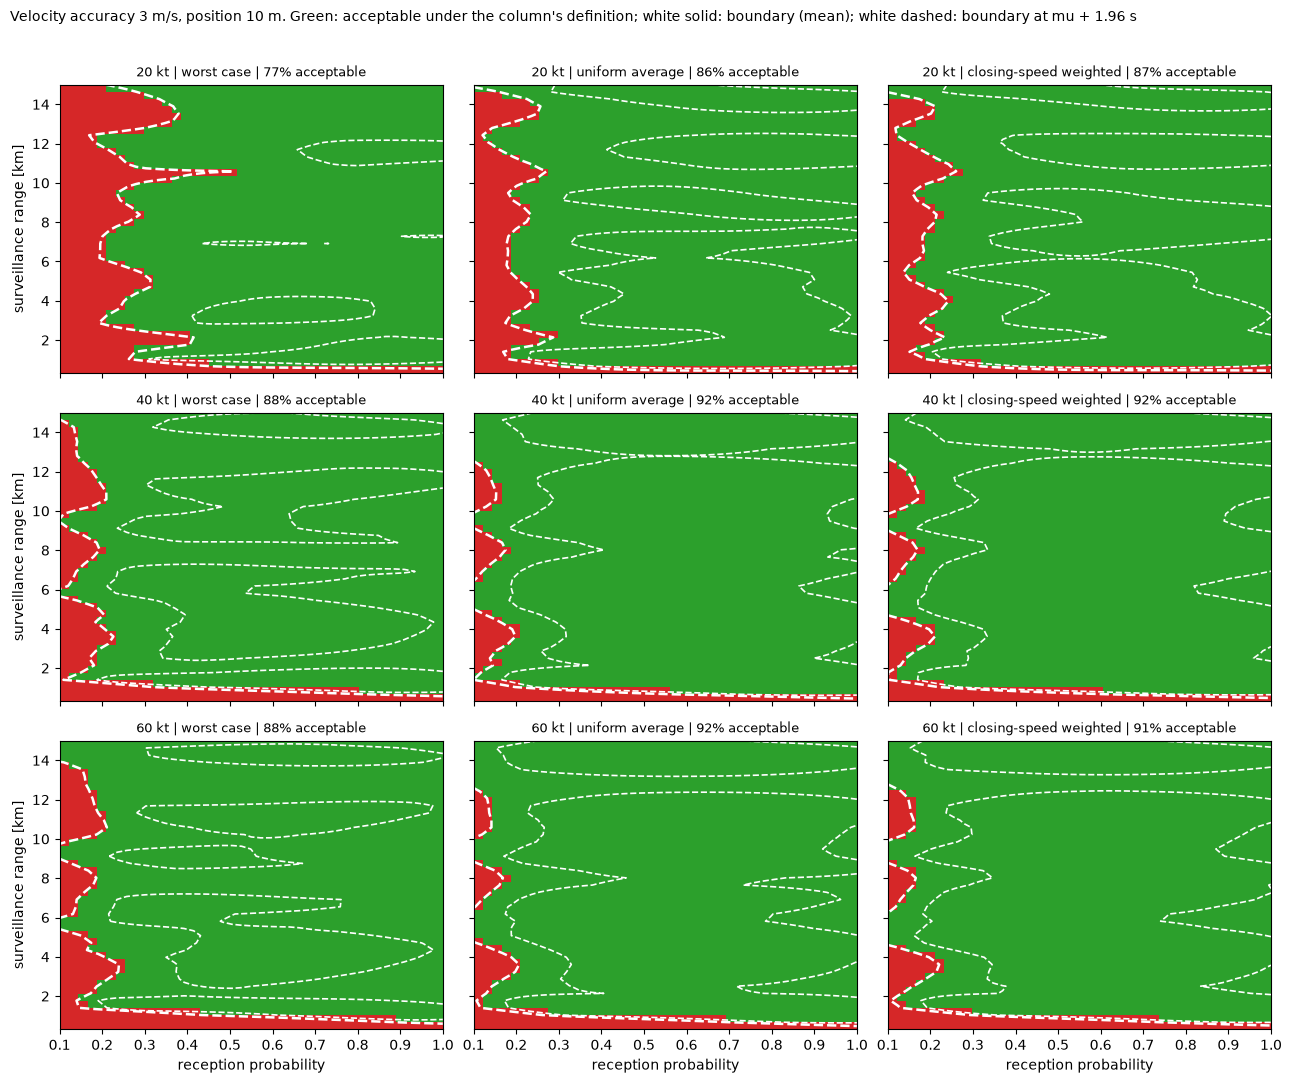

velocity 10 m/s, closing-speed weighted, acceptable share: {'20 kt': 0.0, '40 kt': 0.0, '60 kt': 0.0}


In [9]:
# The same maps under each definition (position accuracy 10 m). Rows: speed class; columns: definition;
# one figure per velocity class that has anything acceptable.
for j, vel in enumerate(levels["vel_ci95"]):
    if vel == 10.0:
        continue                                                     # nothing acceptable under any definition
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharex=True, sharey=True)
    for k, spd in enumerate(levels["speed"]):
        for i, how in enumerate(HOWS):
            ax = axes[k, i]
            g, g_up = aggregate((POS, j, k), how), aggregate((POS, j, k), how, True)
            ax.imshow((g <= TAU).T.astype(float), origin="lower", aspect="auto", cmap=TWO, vmin=0, vmax=1,
                      extent=(phys["p_reception"][0], phys["p_reception"][-1], phys["max_range_m"][0] / 1e3, phys["max_range_m"][-1] / 1e3),
                      interpolation="nearest")
            PR, RR = np.meshgrid(phys["p_reception"], phys["max_range_m"] / 1e3, indexing="ij")
            ax.contour(PR, RR, g, levels=[TAU], colors="white", linewidths=1.8)
            ax.contour(PR, RR, g_up, levels=[TAU], colors="white", linewidths=1.2, linestyles="--")
            ax.set_title(f"{kt(spd)} | {how} | {np.mean(g <= TAU):.0%} acceptable", fontsize=9)
            if k == 2: ax.set_xlabel("reception probability")
            if i == 0: ax.set_ylabel("surveillance range [km]")
    fig.suptitle(f"Velocity accuracy {vel:g} m/s, position 10 m. Green: acceptable under the column's definition; "
                 "white solid: boundary (mean); white dashed: boundary at mu + 1.96 s", x=0.01, ha="left", fontsize=10)
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

# Where does it matter? Velocity 10 m/s under the gentlest definition.
g10 = {kt(levels["speed"][k]): float(np.mean(aggregate((POS, 2, k), "closing-speed weighted") <= TAU)) for k in range(3)}
print("velocity 10 m/s, closing-speed weighted, acceptable share:", g10)

## Safe, ambiguous, unsafe

Three classes from the surrogate's 95% interval under each definition: **safe** (green) where the
upper bound is ≤ 10⁻³, **unsafe** (red) where the lower bound is > 10⁻³, **ambiguous** (orange)
where the interval contains 10⁻³, i.e. where the straddle is still positive.

safe  ambiguous  unsafe
vel_ci95 definition                                     
1.0      worst case              0.44       0.52    0.04
         uniform average         0.76       0.21    0.03
         closing-speed weighted  0.77       0.20    0.03
3.0      worst case              0.27       0.67    0.06
         uniform average         0.59       0.37    0.04
         closing-speed weighted  0.62       0.35    0.04
10.0     worst case              0.00       0.23    0.77
         uniform average         0.00       0.39    0.61
         closing-speed weighted  0.00       0.39    0.61

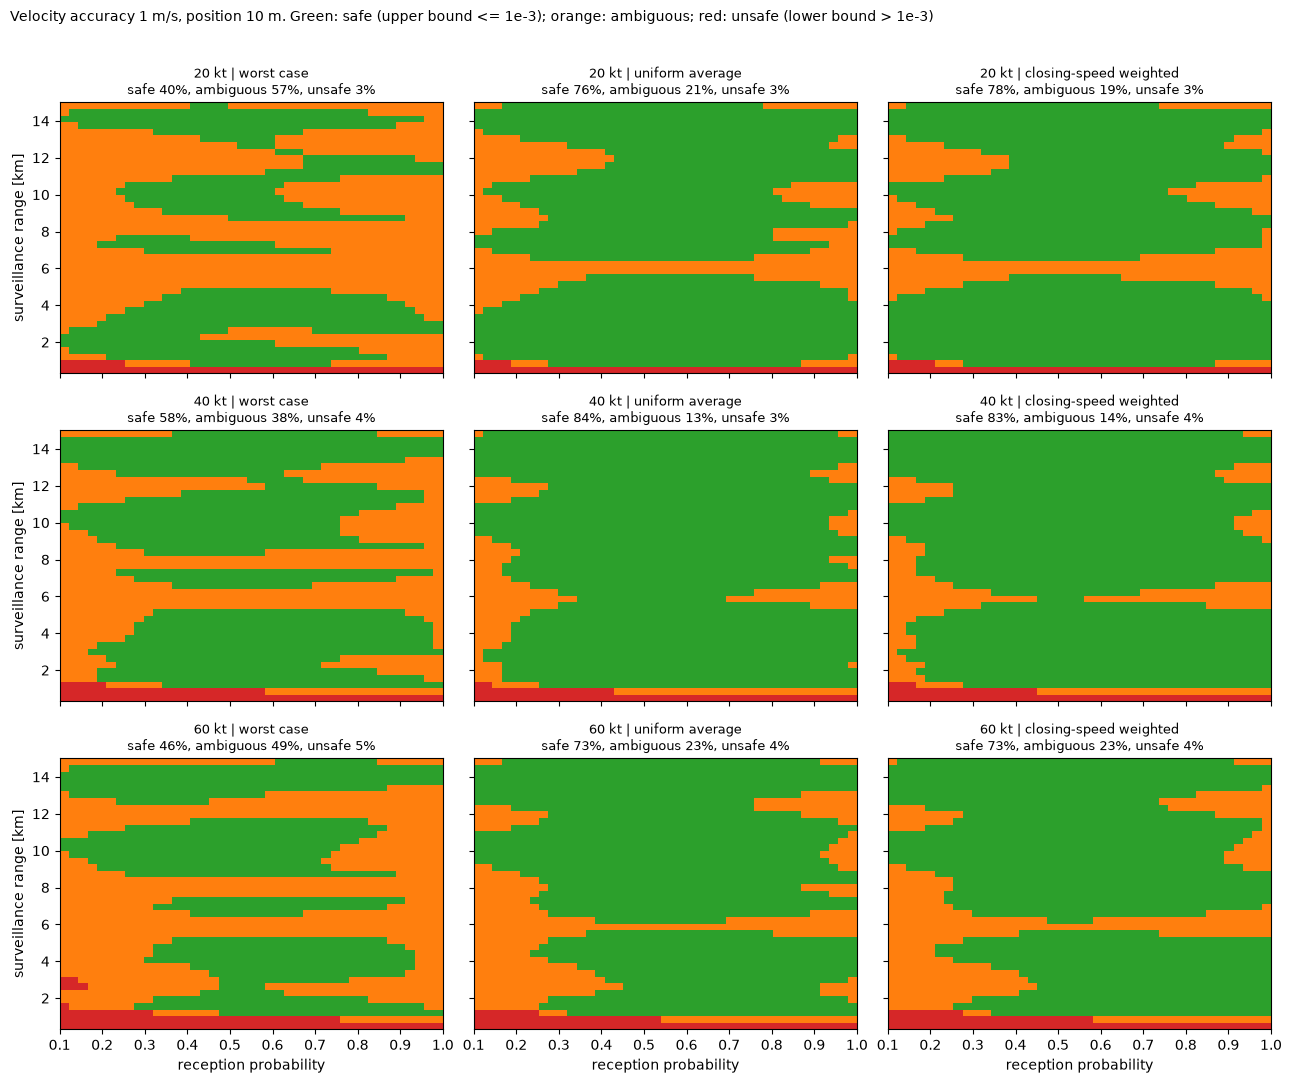

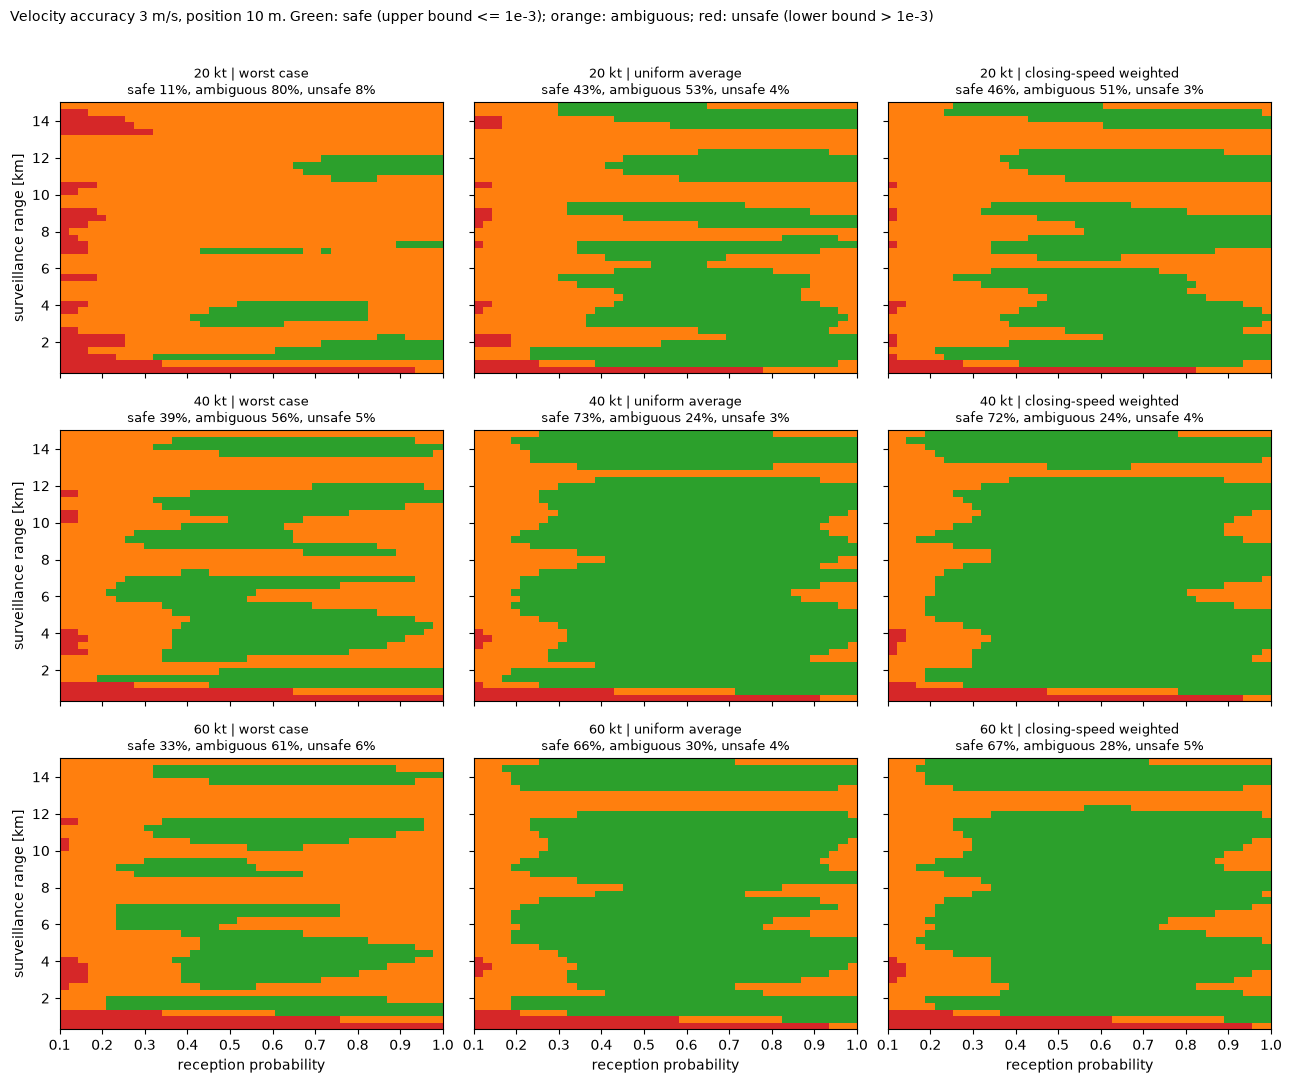

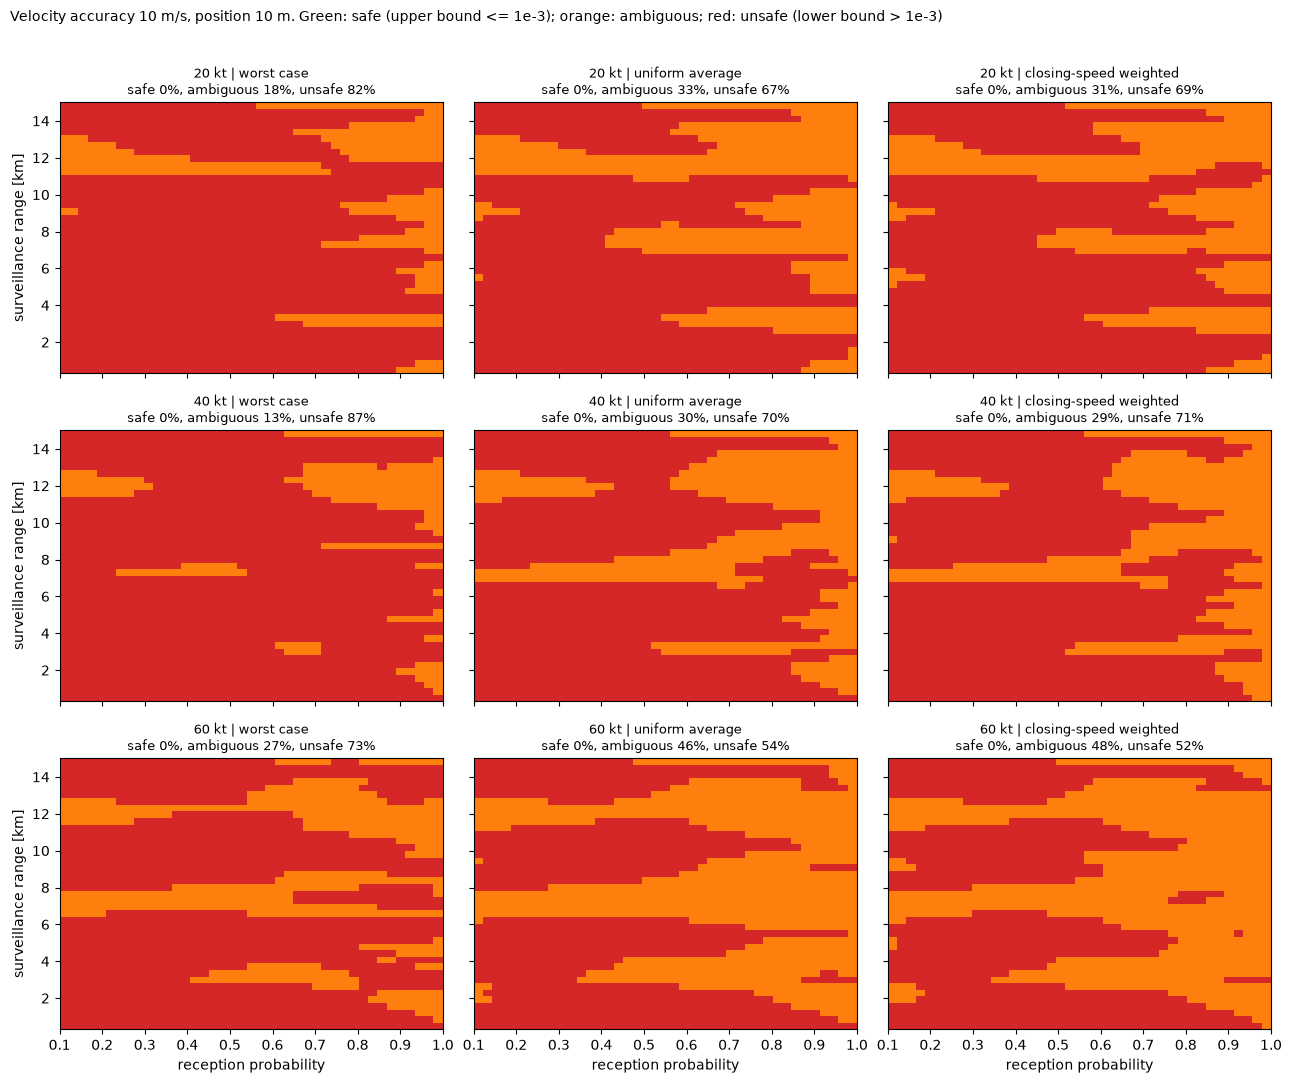

In [10]:
THREE = ListedColormap(["tab:red", "tab:orange", "tab:green"])          # 0 unsafe, 1 ambiguous, 2 safe

def classes(cat, how):
    lo = aggregate_bound(cat, how, -1.96)
    hi = aggregate_bound(cat, how, +1.96)
    return np.where(hi <= TAU, 2, np.where(lo > TAU, 0, 1))

def aggregate_bound(cat, how, z):
    log_p = MU[cat] + z * SD[cat]
    if how == "worst case":
        return log_p.max(axis=-1)
    return np.log10((10.0 ** log_p) @ W[how])

rows = []
for cat in MU:
    ipos, ivel, k = cat
    for how in HOWS:
        c = classes(cat, how)
        rows.append({"definition": how, "speed": kt(levels["speed"][k]), "vel_ci95": levels["vel_ci95"][ivel],
                     "pos_ci95": levels["pos_ci95"][ipos], "safe": np.mean(c == 2), "ambiguous": np.mean(c == 1),
                     "unsafe": np.mean(c == 0)})
three = pd.DataFrame(rows)
three.to_csv("results/exp1_three_classes.csv", index=False)
display(three.groupby(["vel_ci95", "definition"])[["safe", "ambiguous", "unsafe"]].mean().round(2).reindex(HOWS, level=1))

for j, vel in enumerate(levels["vel_ci95"]):
    fig, axes = plt.subplots(3, 3, figsize=(13, 11), sharex=True, sharey=True)
    for k, spd in enumerate(levels["speed"]):
        for i, how in enumerate(HOWS):
            ax = axes[k, i]
            c = classes((POS, j, k), how)
            ax.imshow(c.T, origin="lower", aspect="auto", cmap=THREE, vmin=0, vmax=2, interpolation="nearest",
                      extent=(phys["p_reception"][0], phys["p_reception"][-1], phys["max_range_m"][0] / 1e3, phys["max_range_m"][-1] / 1e3))
            ax.set_title(f"{kt(spd)} | {how}\nsafe {np.mean(c == 2):.0%}, ambiguous {np.mean(c == 1):.0%}, unsafe {np.mean(c == 0):.0%}",
                         fontsize=9)
            if k == 2: ax.set_xlabel("reception probability")
            if i == 0: ax.set_ylabel("surveillance range [km]")
    fig.suptitle(f"Velocity accuracy {vel:g} m/s, position 10 m. Green: safe (upper bound <= 1e-3); orange: ambiguous; "
                 "red: unsafe (lower bound > 1e-3)", x=0.01, ha="left", fontsize=10)
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

## Insight

**1. Velocity accuracy decides the requirement; position accuracy does not.** With a velocity
accuracy of 10 m/s (95%) no combination of reception, range and position accuracy reaches
P(LoS) ≤ 10⁻³, at any speed class: the surrogate's best case is about 5·10⁻³ to 3·10⁻². At 1 m/s,
93–97% of the reception–range plane is acceptable; at 3 m/s, 76–91%. Across the four position
classes (3 m to 92.6 m) the acceptable share barely moves (by at most 0.05), matching the fitted
correlations between position levels of 0.89–0.99: at an RPZ of 150 m the surrogate cannot
tell the position classes apart. The requirement is therefore a velocity requirement first:
velocity accuracy of 3 m/s or better, with reception and range secondary.

**2. Reception and range only bind at the edge of the box.** With good velocity accuracy, the
red region is a thin band below about 1 km of surveillance range; at 3 m/s a reception floor of
roughly 0.15–0.3 appears, highest for the 20 kt class. Above about 1 km, range stops mattering,
as the geometry predicts (the lookahead already flags the conflict before the intruder is that far
away for most headings).

**3. Shallow encounters are the worst, not head-on ones.** At middling CNS quality P(LoS) falls
by one to two orders of magnitude from 2° to 180°. The worst heading over the CNS grid is the
shallowest one for 20 kt (2°), and lies at roughly 25–55° for 40 and 60 kt; at the best CNS the
curves are flat. For exp2 (20 kt) this supports the 2° heading as the worst case; 180° is the
benign end, not a second worst case.

**4. The slowest class is the hardest.** The 20 kt multirotor has the smallest acceptable share at
3 m/s (0.76–0.81, against 0.86–0.91 for 40 and 60 kt) and the highest P(LoS) at middling CNS and with poor velocity accuracy (at the best CNS the three
classes coincide), consistent with the earlier Chapter 8 campaign.

**5. The boundary is not resolved after 250 samples.** The maximum straddle never fell below
zero (final +1.48), and 10–30% of the monitor points still have a 95% interval that contains
10⁻³. Read at the conservative μ + 1.96 s instead of μ, the acceptable share drops to 0.11–0.61.
With 36 categories, 250 samples is about 7 per category. The qualitative findings (1–4) hold in
both readings; the exact location of the reception floor at 3 m/s does not.

**6. The definition over the heading matters only where velocity accuracy is marginal.**
Comparing the worst case with the two averages over the heading (acceptable share of the
reception–range plane, surrogate mean, averaged over position classes):

| velocity accuracy | worst case | uniform average | closing-speed weighted |
|---|---|---|---|
| 1 m/s | 0.93–0.97 | 0.95–0.97 | 0.95–0.97 |
| 3 m/s | 0.78–0.89 | 0.87–0.93 | 0.89–0.93 |
| 10 m/s | 0 | 0 | 0 |

The velocity requirement (3 m/s or better) holds under every definition: at 10 m/s nothing is
acceptable even when shallow conflicts are down-weighted. At 3 m/s the worst case is visibly
stricter for the 20 kt class (0.78 against 0.87–0.89), because it is set by the shallowest heading
in the box, 2°, the edge of the experiment rather than a property of the CNS. The two averages
agree with each other within 0.02, even though the closing-speed weighting gives headings below 20°
only 1.4% of the weight against 10.8%: the result is sensitive to *whether* the heading is averaged,
not to *how*. Read conservatively (μ + 1.96 s), the gap widens (worst case 0.10–0.54, averages
0.42–0.82): the surrogate's uncertainty is largest exactly at the shallow headings the worst case
picks, so the worst-case requirement is both the strictest and the least certain.

*Caveats.* The surrogate treats every Monte Carlo estimate as exact (Section 4.1). The 60 kt
class flies above its fixed-wing speed window, so part of its result is MVP speed clipping. The
negative correlation between velocity levels 1 and 10 m/s (−0.27) says the two levels vary
differently across the box, not that worse velocity accuracy helps.
